# Explainability — Why does the model predict pneumonia?

High recall alone does not tell us whether the ResNet-18 (`train_optimized.py`) looks at the **lungs** or at **shortcuts** such as text markers, hospital labels or image borders. This notebook explains the model's predictions with two methods:

1. **Grad-CAM** — uses the gradients of the predicted class flowing into the last convolutional block (`layer4`) to highlight the regions that drove the decision.
2. **Occlusion sensitivity** — hides one 15×15 patch at a time and measures how much the pneumonia probability drops. It does not depend on gradients, so it cross-checks Grad-CAM.

All code lives in `src/explainability/gradcam.py`; `explain.py` runs the full analysis from the command line.

**Prerequisite:** the dataset extracted to `data/interim/chest_xray` (see `setup.ipynb`) and `pneumonia_resnet18_recall_optimized.pth` in the repo root.

In [1]:
import torch
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage

from src.explainability.gradcam import GradCAM, load_resnet18, border_fraction, denormalize, occlusion_sensitivity
from src.dataset import DATA_DIR, test_transform

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
model = load_resnet18("pneumonia_resnet18_recall_optimized.pth", device)

## 1. Run Grad-CAM on the whole test set

This writes per-outcome figures to `reports/figures/explainability/` and a per-image table to `reports/explainability_summary.csv`.

In [2]:
!python explain.py --split test --image-size 150 --num-examples 4 --num-occlusion 2

Explained 624 images from data/interim/chest_xray/test
outcome           count   mean border attention
true_positive       378                   0.493
true_negative       101                   0.300
false_positive      133                   0.588
false_negative       12                   0.318
Saved summary to reports/explainability_summary.csv and figures to reports/figures/explainability


## 2. Inspect each outcome group

- **True positives / true negatives:** does the heatmap sit inside the lung fields?
- **False negatives (missed pneumonia):** the most dangerous errors — what did the model look at instead?
- **False positives:** with `pos_weight=3` and threshold 0.4 the model leans towards pneumonia; check whether these are driven by real opacities or by artefacts.

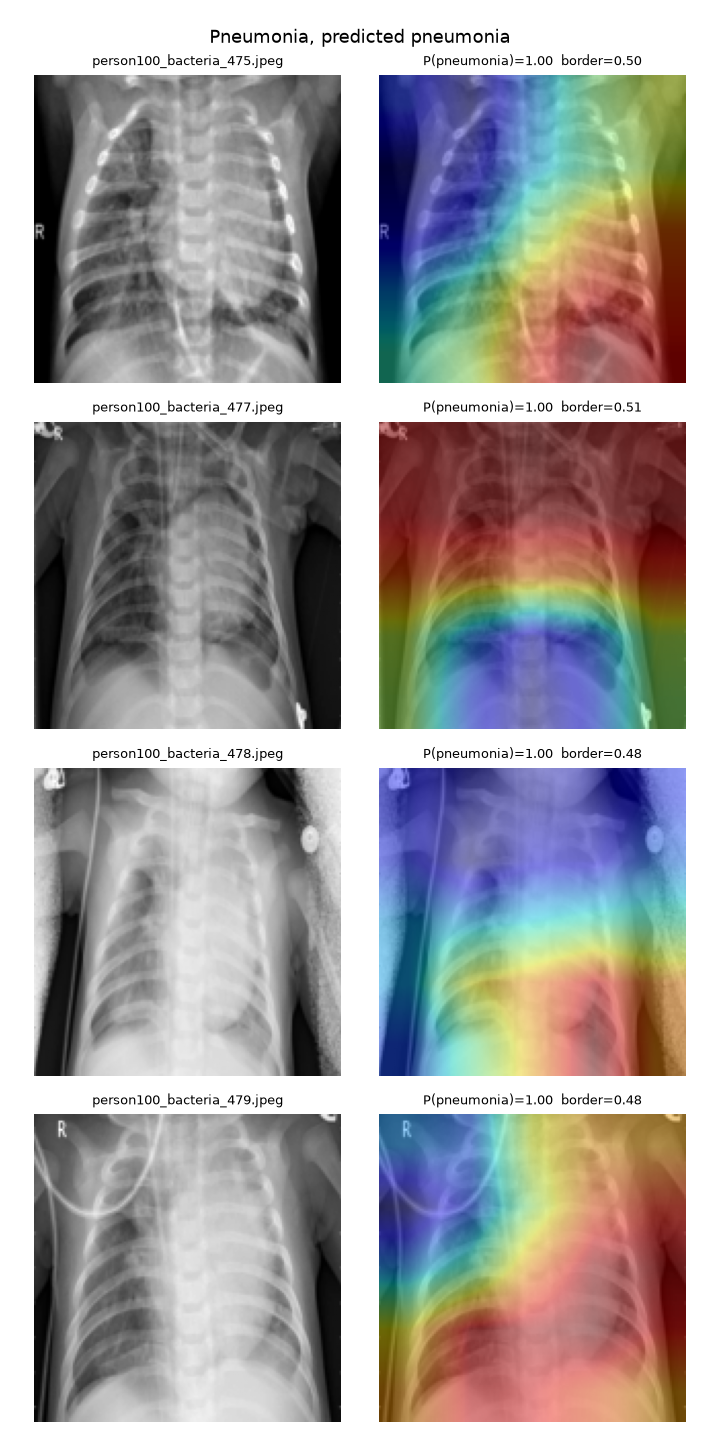

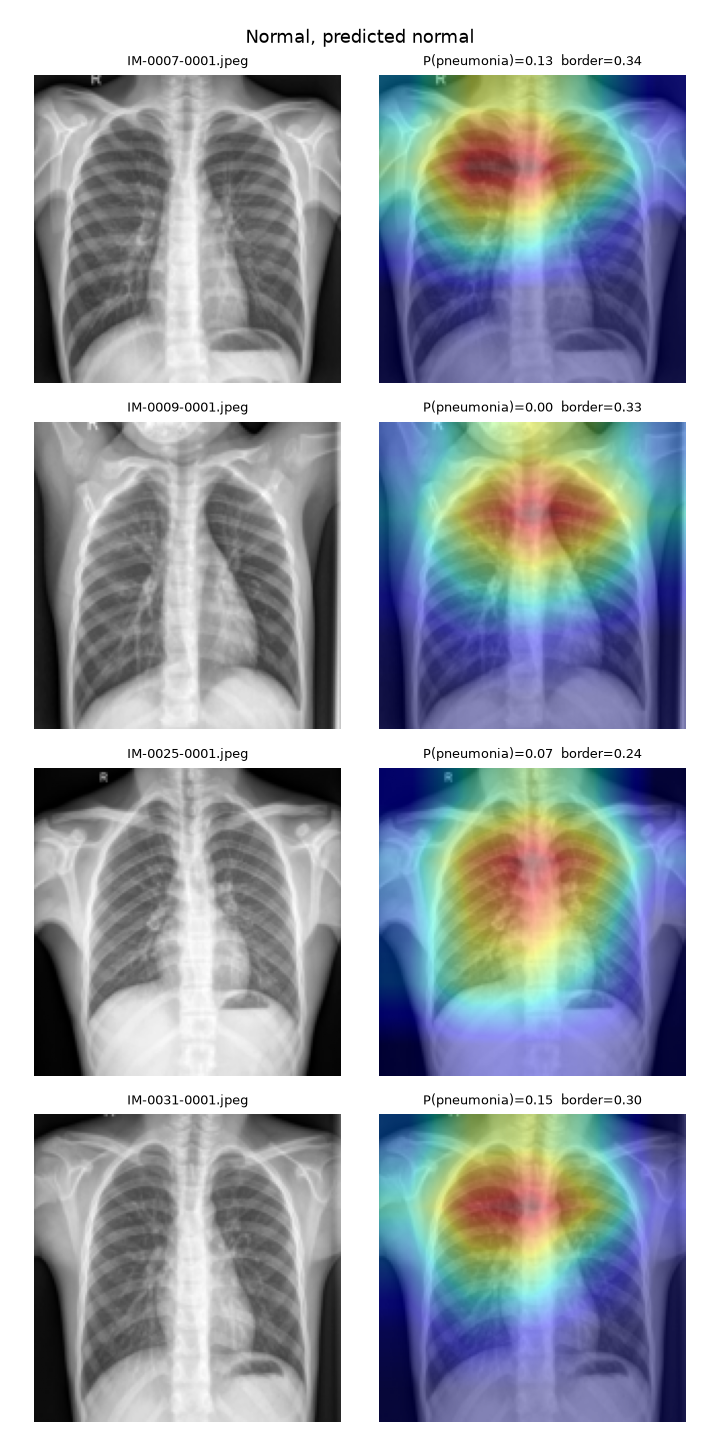

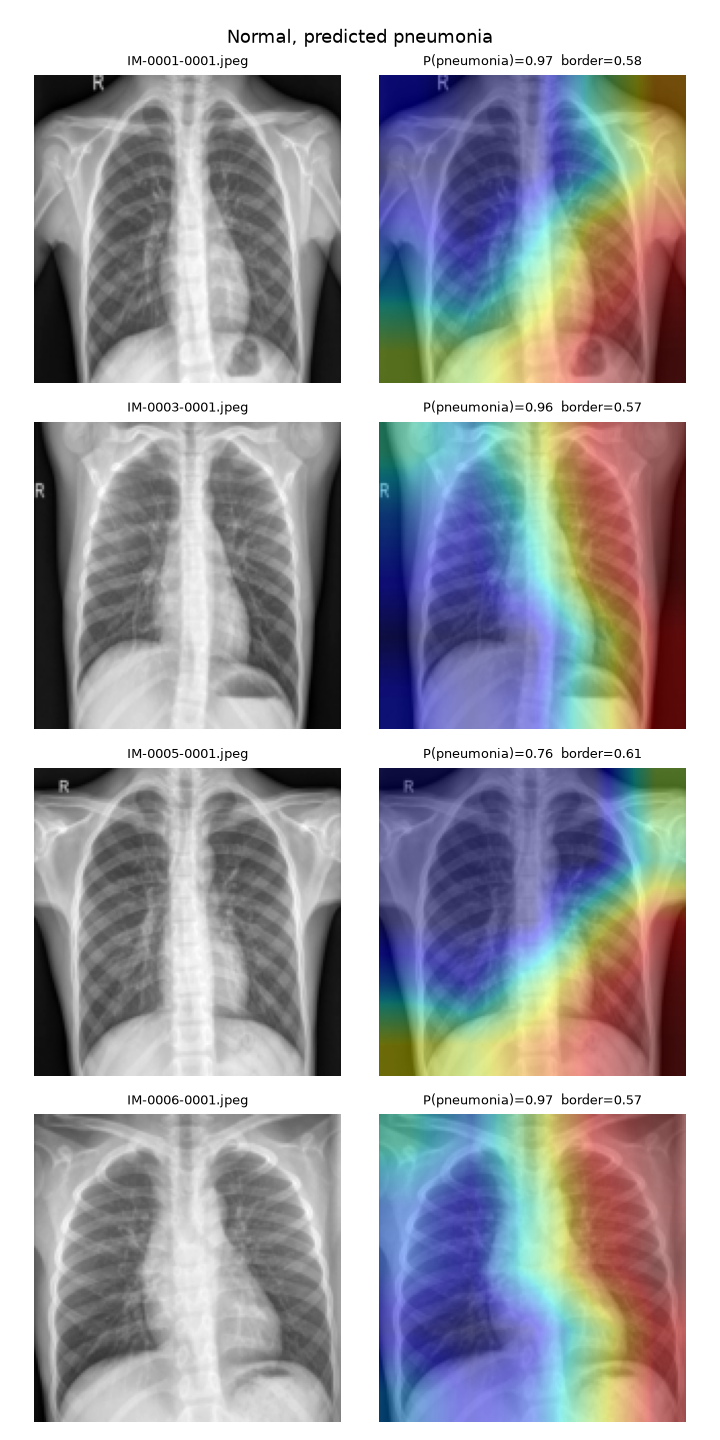

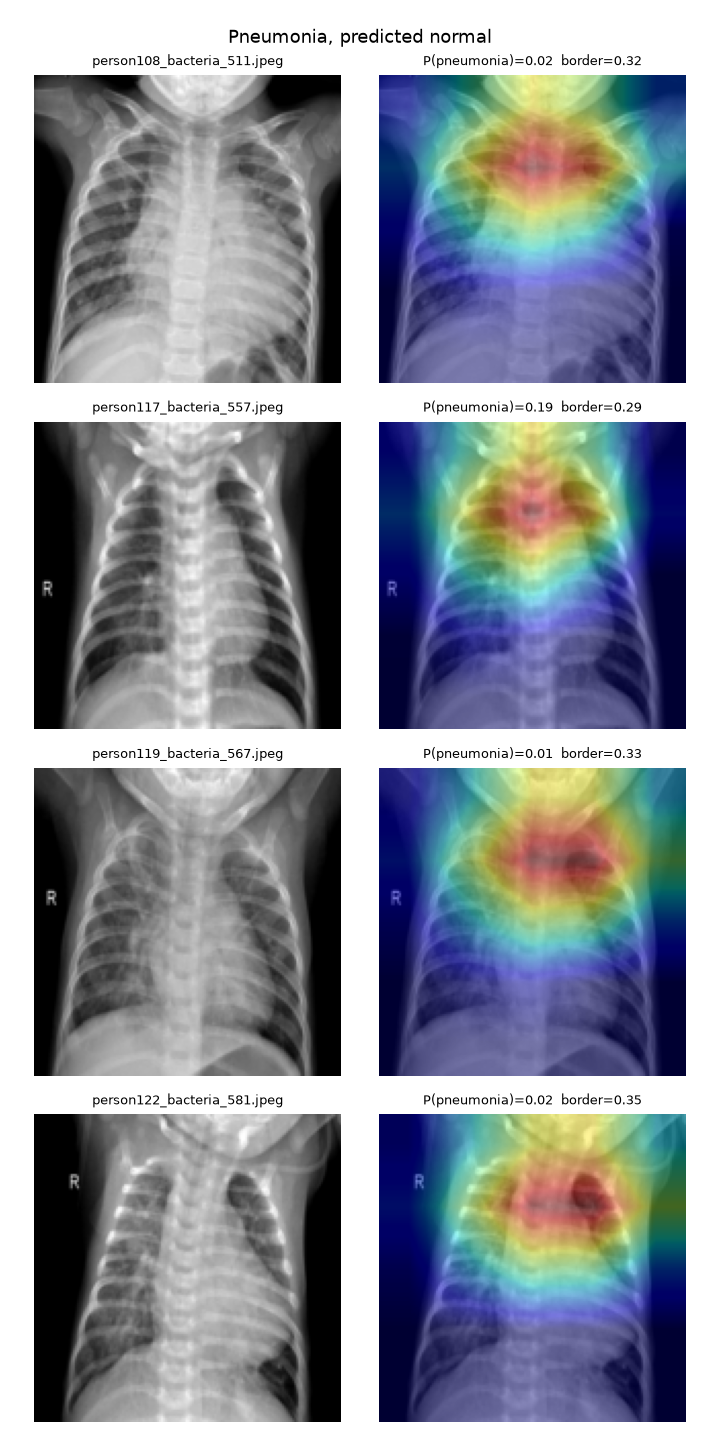

In [3]:
for group in ["true_positive", "true_negative", "false_positive", "false_negative"]:
    try:
        display(ShowImage(f"reports/figures/explainability/{group}.png", width=450))
    except FileNotFoundError:
        print(f"No {group} examples")

## 3. Grad-CAM vs. occlusion

If both methods highlight the same area, the explanation is more trustworthy. Red in the occlusion map means hiding that patch *lowered* the pneumonia probability, i.e. the patch supported a pneumonia prediction.

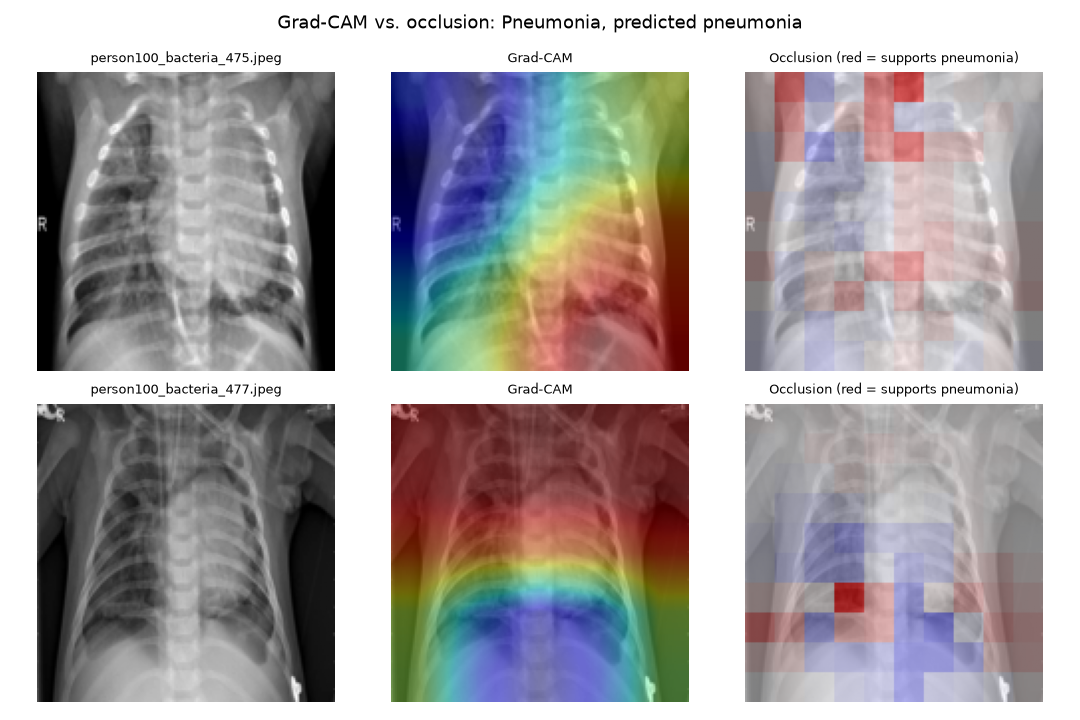

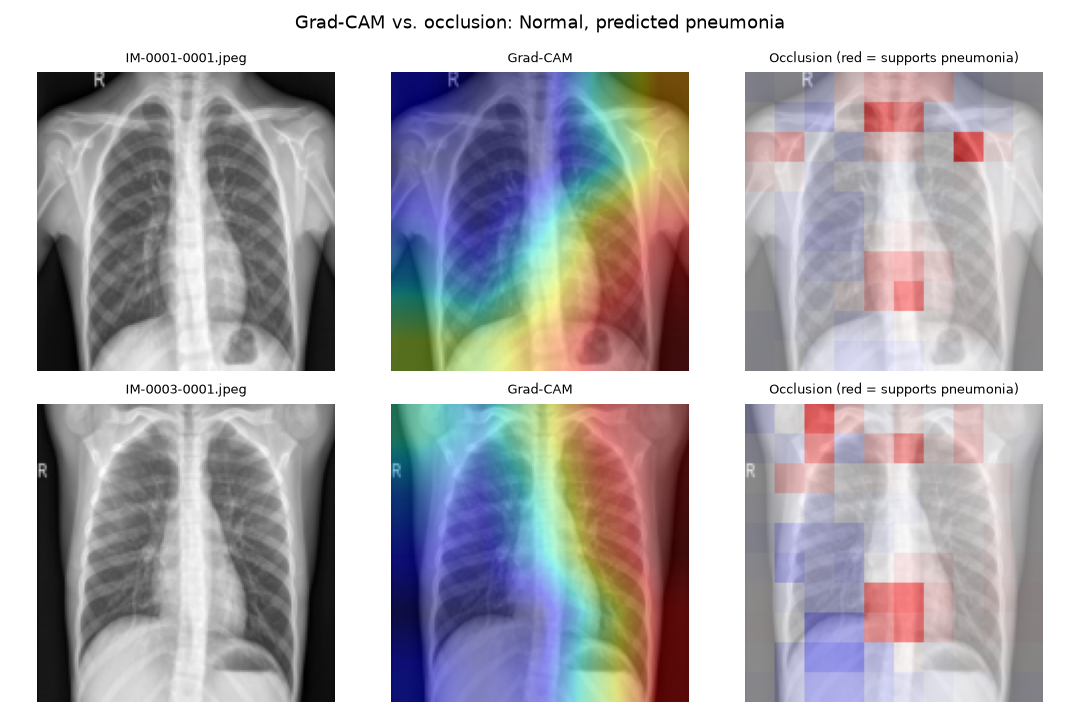

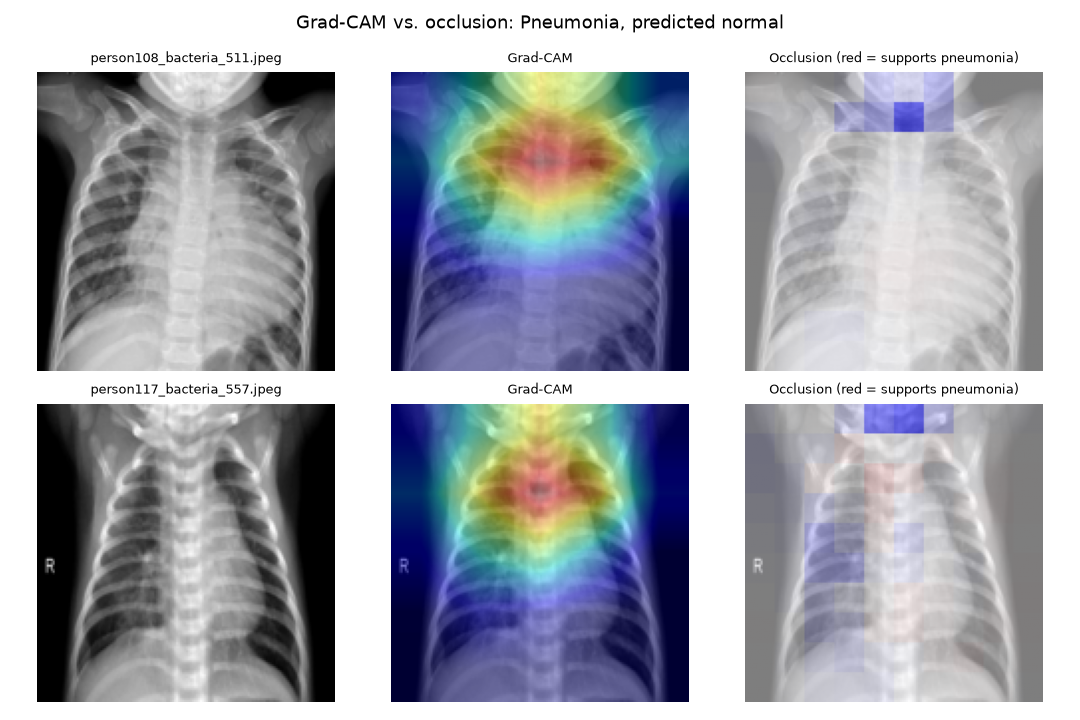

In [4]:
for group in ["true_positive", "false_positive", "false_negative"]:
    try:
        display(ShowImage(f"reports/figures/explainability/occlusion_{group}.png", width=650))
    except FileNotFoundError:
        print(f"No {group} examples")

## 4. Shortcut check: how much attention falls on the image border?

`cam_border_fraction` is the share of the Grad-CAM heatmap lying in the outer 15% band of the image. Lungs are central; markers, labels and scanner edges are near the border.

For reference, a perfectly flat heatmap gives **≈ 0.51** (the band covers 51% of the image area). Values clearly below that mean attention is concentrated centrally; values near or above it suggest the model is using border artefacts.

,count,mean,std,min,25%,50%,75%,max
outcome,,,,,,,,
false_negative,12.0,0.318208,0.020532,0.2861,0.305525,0.3167,0.332475,0.3524
false_positive,133.0,0.588438,0.073850,0.3765,0.534600,0.5775,0.627400,0.7959
true_negative,101.0,0.299901,0.026065,0.2078,0.290200,0.3049,0.314700,0.3441
true_positive,378.0,0.493396,0.046896,0.3526,0.469500,0.4960,0.517650,0.7147


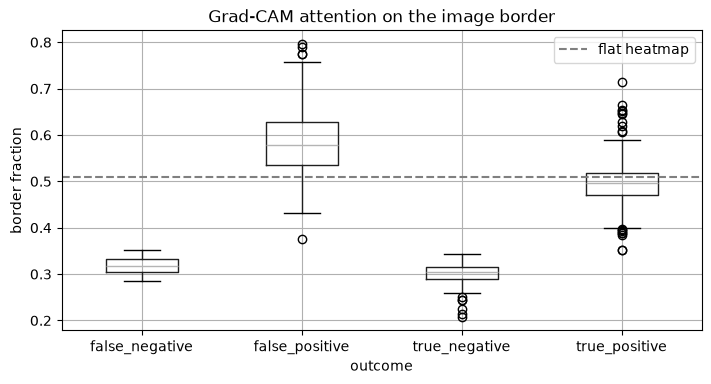

In [5]:
import pandas as pd

summary = pd.read_csv("reports/explainability_summary.csv")
display(summary.groupby("outcome")["cam_border_fraction"].describe())

summary.boxplot(column="cam_border_fraction", by="outcome", figsize=(8, 4))
plt.axhline(0.51, color="gray", linestyle="--", label="flat heatmap")
plt.suptitle("")
plt.title("Grad-CAM attention on the image border")
plt.ylabel("border fraction")
plt.legend()
plt.show()

In [6]:
# Images where the model looks most at the border — inspect these for shortcuts
summary.sort_values("cam_border_fraction", ascending=False).head(10)

,filename,label,prob_pneumonia,prediction,outcome,cam_border_fraction
74,NORMAL2-IM-0027-0001.jpeg,NORMAL,0.4121,PNEUMONIA,false_positive,0.7959
180,NORMAL2-IM-0313-0001.jpeg,NORMAL,0.4172,PNEUMONIA,false_positive,0.7906
50,IM-0083-0001.jpeg,NORMAL,0.4662,PNEUMONIA,false_positive,0.7750
210,NORMAL2-IM-0350-0001.jpeg,NORMAL,0.4872,PNEUMONIA,false_positive,0.7737
201,NORMAL2-IM-0339-0001.jpeg,NORMAL,0.4889,PNEUMONIA,false_positive,0.7566
163,NORMAL2-IM-0288-0001.jpeg,NORMAL,0.6752,PNEUMONIA,false_positive,0.7453
169,NORMAL2-IM-0300-0001.jpeg,NORMAL,0.4869,PNEUMONIA,false_positive,0.7292
220,NORMAL2-IM-0364-0001.jpeg,NORMAL,0.7488,PNEUMONIA,false_positive,0.7164
288,person119_bacteria_568.jpeg,PNEUMONIA,0.4636,PNEUMONIA,true_positive,0.7147
115,NORMAL2-IM-0150-0001.jpeg,NORMAL,0.5164,PNEUMONIA,false_positive,0.7124


## 5. Explain a single X-ray

Prediction: PNEUMONIA, P(pneumonia)=0.9992, border attention=0.503
Saved reports/figures/explainability/single_person100_bacteria_475.png


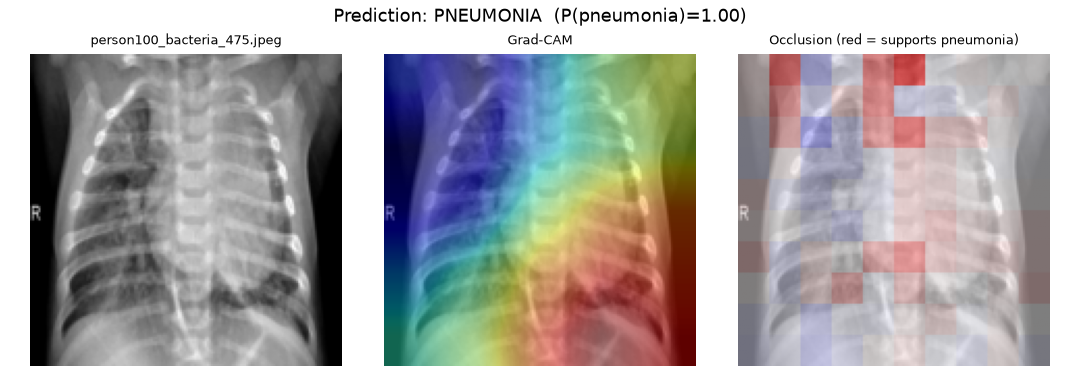

In [7]:
import os
example = os.path.join(DATA_DIR, "test", "PNEUMONIA", sorted(os.listdir(os.path.join(DATA_DIR, "test", "PNEUMONIA")))[0])
!python explain.py --image-size 150 --image "{example}"
display(ShowImage(f"reports/figures/explainability/single_{os.path.splitext(os.path.basename(example))[0]}.png", width=650))

## 6. What the predictions look like

The explainability table also gives the full confusion matrix, which shows what the 96.92% recall in the README does not: the cost in false alarms.

In [8]:
y = summary["label"] == "PNEUMONIA"
print(summary["outcome"].value_counts())
for t in [0.4, 0.5, 0.7, 0.9, 0.95, 0.99]:
    p = summary["prob_pneumonia"] >= t
    print(f"threshold {t:.2f}: recall {(p & y).sum() / y.sum():.3f}  specificity {(~p & ~y).sum() / (~y).sum():.3f}")

outcome
true_positive     378
false_positive    133
true_negative     101
false_negative     12
Name: count, dtype: int64
threshold 0.40: recall 0.969  specificity 0.432
threshold 0.50: recall 0.967  specificity 0.457
threshold 0.70: recall 0.962  specificity 0.500
threshold 0.90: recall 0.946  specificity 0.590
threshold 0.95: recall 0.933  specificity 0.684
threshold 0.99: recall 0.895  specificity 0.816


## 7. Findings

Results for `pneumonia_resnet18_recall_optimized.pth` on the 624 test images, threshold 0.4.

**1. High recall comes with very low specificity.**
Recall is 378 / 390 = **96.9%**, matching the README. But only 101 of 234 normal X-rays are classified correctly (**specificity 43.2%**); 133 healthy patients would be flagged as pneumonia, and 96 of them get P(pneumonia) ≥ 0.9. Overall accuracy is 76.8%. The model is biased towards pneumonia by design (`pos_weight=3` on the class that is already 73% of the data, plus a 0.4 threshold).

**2. The heatmaps are diffuse, not focused on lung opacities.**
For true positives, Grad-CAM covers broad regions of the image (mean border fraction 0.49, close to the 0.51 of a flat heatmap) instead of localised consolidation. Pneumonia predictions are being made from global image appearance rather than specific findings.

**3. False positives are driven by regions outside the lungs.**
Normal X-rays wrongly called pneumonia have the highest border attention of any group (mean **0.59**, above the flat baseline): the heatmap sits on the image edges, the background beside the chest and the area below the diaphragm. Occlusion agrees only partly — the patches that push these images towards pneumonia are mostly the neck/clavicle area and the heart, not the lung fields.

**4. Normal predictions look at one fixed place.**
Every NORMAL prediction (true negatives and the 12 missed pneumonia cases) has border fraction ≤ 0.35, with attention concentrated on the upper-central chest (trachea / upper mediastinum). The missed pneumonia cases show the same pattern: the model looked at the upper mediastinum and did not attend to the lower lung zones where the opacities are.

**5. The 100% validation recall is not meaningful.**
The official validation split has only 8 pneumonia images, so it cannot support threshold or model selection.

### Recommendations for the training team
- Train for several epochs (`train_optimized.py` runs a single pass over the training data).
- Remove or invert `pos_weight` — pneumonia is the majority class; a balancing weight would be ≈ 0.35, not 3.
- Create a real validation split (~10–15% of `train/`, stratified) and choose the threshold there. On the test set, raising the threshold to 0.99 would give recall 89.5% / specificity 81.6%, but picking it on test data would be leakage.
- Report specificity, precision and a confusion matrix alongside recall.
- Use ImageNet normalisation for the pretrained ResNet, and re-run `explain.py` after retraining to check that attention moves onto the lung fields.